# Does the Flight + Hotel Package Increase Bookings? A Causal Analysis of Expedia Data

**Question:** Package searches (flight + hotel) have a lower booking rate than hotel-only searches. Is this caused by the package, or by the type of customer who chooses it?

**Data:** [Kaggle – Expedia Hotel Recommendations](https://www.kaggle.com/competitions/expedia-hotel-recommendations/data) (`train.csv`, `destinations.csv`)

**Result:** Without adjustment, package searches have about **5 fewer bookings per 100 clicks**. After controlling for customer differences, the package itself accounts for about **2 fewer**.

## Overview

| Section | What I do | Result |
|---|---|---|
| **0. Packages** | Load libraries | – |
| **1. Load and sample** | Take a 1% stratified sample of 37.7 million searches | 376,703 rows |
| **2. Clean** | Add destination features, drop unmatched rows, fill missing distances | 375,024 rows |
| **3. Control variables** | Control the factors that exist before the package choice | 162 variables |
| **4. Model input** | Turn category columns into yes/no columns | 238 columns |
| **5. Model and Identify** | State the key assumption | – |
| **6. Simple comparison** | Compare booking rates with no adjustment | −4.9 bookings per 100 clicks |
| **7. Estimate** | Linear regression and propensity score weighting | −2.1 bookings per 100 clicks (ATT) |
| **8. Refute** | Three stress tests | Effect disappears with a fake treatment; stays the same with noise or less data |
| **9. Results** | Interpretation and next steps | – |

### Method

The notebook follows the four steps of Microsoft's **DoWhy** library: Model (Section 3) → Identify (5) → Estimate (6–7) → Refute (8). A senior data scientist in the Data Science Association Mentorship Program recommended this framework to me. DoWhy 0.8, the version available for Python 3.14, does not work with pandas 3, so I implemented each step with pandas, NumPy and scikit-learn.

## 0. Packages

pandas and NumPy for data, matplotlib for charts, scikit-learn for models.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## 1. Load and sample the data

`train.csv` has 37.7 million search events. About 8% are bookings (`is_booking = 1`); the rest are clicks.

I take 1% of the bookings and 1% of the clicks separately (stratified sampling), so the sample keeps the same booking rate. `random_state` makes the sample reproducible.

In [3]:
print("1. Reading train.csv ...")
train_df = pd.read_csv('train.csv')
print("Rows and columns:", train_df.shape)
print("Booking rate in the full data:\n", train_df['is_booking'].value_counts(normalize=True))

1. Reading train.csv ...
Rows and columns: (37670293, 24)
Booking rate in the full data:
 is_booking
0    0.920343
1    0.079657
Name: proportion, dtype: float64


In [4]:
# Stratified sampling: take 1% from the clicks (is_booking = 0) and 1% from the bookings (is_booking = 1)
train_sample = train_df.groupby('is_booking').sample(frac=0.01, random_state=966)
print(f"Rows after sampling: {train_sample.shape[0]}")
print("Check that the booking rate is the same:\n", train_sample['is_booking'].value_counts(normalize=True))

# We do not need the full 37.7 million rows anymore. Delete them to free memory.
del train_df

Rows after sampling: 376703
Check that the booking rate is the same:
 is_booking
0    0.920343
1    0.079657
Name: proportion, dtype: float64


## 2. Clean the data

1. **Destination features:** join the 149 features (`d1`–`d149`) from `destinations.csv`. Expedia derived them from hotel reviews; they describe each destination.
2. **Unmatched rows:** 0.4% of rows have no destination match and are removed.
3. **Missing distances:** 36% of `orig_destination_distance` is missing, too many to remove. I fill these with the median and add `distance_missing` (1 = filled in), so the model can tell filled values from real ones.

In [5]:
# Join the destination features (d1–d149)
dest_df = pd.read_csv('destinations.csv')
merged_df = pd.merge(train_sample, dest_df, on='srch_destination_id', how='left')
print(f"Shape after the join: {merged_df.shape}")

# Rows with no destination match: check the share, then remove them
missing_rate = merged_df['d1'].isna().mean()
print(f"Share of rows with no destination match: {missing_rate:.1%}")
merged_df = merged_df.dropna(subset=['d1']).reset_index(drop=True).copy()
print(f"Shape after removing them: {merged_df.shape}")

Shape after the join: (376703, 173)
Share of rows with no destination match: 0.4%
Shape after removing them: (375024, 173)


In [6]:
# Missing distances: fill with the median, and add a column that marks "this value was empty"
print(f"Share of missing distances: {merged_df['orig_destination_distance'].isna().mean():.1%}")
merged_df['distance_missing'] = merged_df['orig_destination_distance'].isna().astype(int)
merged_df['orig_destination_distance'] = merged_df['orig_destination_distance'].fillna(
    merged_df['orig_destination_distance'].median()
)

Share of missing distances: 35.9%


## 3. Choose the control variables

**Rule:** follow the order of a customer's visit.

- **Before** the package choice → **control**. These factors can affect both the choice and the booking.
- **After** the choice → **do not control**. They are part of the package's effect.

| Stage | Variables | Decision |
|---|---|---|
| 1. Who the user is | website, website continent, user country | Control |
| 2. What they search for | device, channel, adults, children, rooms, destination type, hotel continent and country, distance, `d1`–`d149` | Control |
| After the choice | `hotel_cluster` (hotel clicked), `cnt` (events in the session) | Do not control |
| Order unclear | `srch_ci`, `srch_co` (check-in and check-out dates), `date_time` | Do not control |
| Detailed IDs | `user_id`, `user_location_region`, `user_location_city`, `srch_destination_id`, `hotel_market` | Do not control |

**Why drop the detailed IDs?** An ID number has no size meaning (city #5000 is not "more" than city #10), and there are tens of thousands of them. Location is already covered by user country, hotel country and `d1`–`d149`. `user_id` identifies a person but describes nothing about them.

In [7]:
treatment = 'is_package'   # cause: is this a package search?
outcome = 'is_booking'     # result: did it become a booking?

# Stage 1: who the user is (fixed before the visit) -> control
phase1_background = ['site_name', 'posa_continent', 'user_location_country']

# Stage 2: what they search for (set before choosing a package) -> control
phase2_intent = [
    'is_mobile', 'channel',
    'srch_adults_cnt', 'srch_children_cnt', 'srch_rm_cnt',
    'srch_destination_type_id', 'hotel_continent', 'hotel_country',
    'orig_destination_distance', 'distance_missing'
]

# Destination features -> control
destination_features = [f'd{i}' for i in range(1, 150)]

# Not controlled (listed here only as a record; they do not go into the model)
excluded = [
    'hotel_cluster', 'cnt',                      # happen after the choice
    'srch_ci', 'srch_co', 'date_time',           # order not clear
    'user_id', 'user_location_region', 'user_location_city',
    'srch_destination_id', 'hotel_market'        # ID numbers that are too detailed
]

confounders = phase1_background + phase2_intent + destination_features
print(f"Number of control variables: {len(confounders)}")

Number of control variables: 162


## 4. Prepare the model input

Some columns are numbers that stand for categories: `user_location_country = 66` means "country no. 66", not an amount. I turn these into yes/no columns (one-hot encoding). To limit the number of columns, I keep the 20 most common values in each column and group the rest as "other".

- **Category columns:** website, continents, countries, channel, destination type
- **Number columns:** used as they are

In [8]:
# In these columns the numbers are categories, not amounts
categorical_cols = [
    'site_name', 'posa_continent', 'user_location_country', 'channel',
    'srch_destination_type_id', 'hotel_continent', 'hotel_country'
]
# All other control variables are real numbers; use them as they are
numeric_cols = [c for c in confounders if c not in categorical_cols]


def keep_top(column, n=20):
    """Keep the n most common categories. Change all others to -1 (= "other")."""
    top_categories = column.value_counts().index[:n]
    return column.where(column.isin(top_categories), other=-1)


# Clean the category columns, then split them into yes/no columns
categories = merged_df[categorical_cols].apply(keep_top).astype(str)
dummies = pd.get_dummies(categories, drop_first=True, dtype=float)

# Final model input: number columns + yes/no columns
X = pd.concat([merged_df[numeric_cols], dummies], axis=1).astype('float32')
t = merged_df[treatment].to_numpy()   # cause: 0 = hotel only, 1 = package
y = merged_df[outcome].to_numpy()     # result: 0 = click only, 1 = booking

print(f"Model input: {X.shape[0]:,} rows, {X.shape[1]} columns")

Model input: 375,024 rows, 238 columns


## 5. Model and Identify

**Model** is Section 3: the cause, the outcome and the control variables.

**Identify:** the effect can be measured by comparing package and hotel-only searches **among people with the same control variables** (backdoor adjustment).

**Key assumption:** the control variables include every factor that affects both the package choice and the booking. A missing factor (e.g. "already decided to travel") would bias the result. The data cannot test this; it is the main limitation.

## 6. Simple comparison

Booking rate of package searches minus hotel-only searches, with no adjustment. This is the number a standard report would show.

In [9]:
rate_package = y[t == 1].mean()   # booking rate of package searches
rate_hotel = y[t == 0].mean()     # booking rate of hotel-only searches
naive_effect = rate_package - rate_hotel

print(f"Booking rate, package:     {rate_package:.2%}")
print(f"Booking rate, hotel only:  {rate_hotel:.2%}")
print(f"Simple difference:         {naive_effect * 100:+.2f} percentage points")

Booking rate, package:     4.31%
Booking rate, hotel only:  9.18%
Simple difference:         -4.87 percentage points


## 7. Estimate the effect

Both methods remove customer differences so that only the package effect remains.

### Method 1: Linear regression

Regress booking on the package indicator and all control variables. The package coefficient is the effect when everything else is equal. Fast and simple, but it assumes linear effects.

In [10]:
# Put "package or not" in the first column, then all control variables
X_with_treatment = np.column_stack([t, X])

linear_model = LinearRegression().fit(X_with_treatment, y)
effect_linear = linear_model.coef_[0]   # the coefficient of the first column (package) is the effect

print(f"Linear regression: a package changes the booking chance by {effect_linear * 100:+.2f} percentage points")

Linear regression: a package changes the booking chance by -2.74 percentage points


### Method 2: Propensity score weighting

1. **Propensity score:** logistic regression predicts each person's probability of choosing a package from their background.
2. **Weighting:** reweight people so both groups have the same background mix, then compare booking rates.

Two estimands:

- **ATE:** the effect if *everyone* used a package vs. no one.
- **ATT:** the effect for the people who *actually* chose a package. This is the more relevant number for evaluating an existing feature.

In [11]:
def ipw_effect(X, t, y):
    """Propensity score weighting. Returns the ATE, the ATT, and each person's propensity score."""

    # Step 1: predict how likely each person is to choose a package (the propensity score)
    #   StandardScaler puts all columns on the same scale so logistic regression works well
    propensity_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    propensity_model.fit(X, t)
    ps = propensity_model.predict_proba(X)[:, 1]

    # Avoid extreme values: scores very close to 0 or 1 would create huge weights
    ps = np.clip(ps, 0.01, 0.99)

    # Step 2 (ATE): package users get weight 1 / ps, hotel-only users get weight 1 / (1 - ps)
    w_package = t / ps
    w_hotel = (1 - t) / (1 - ps)
    rate_package = (w_package * y).sum() / w_package.sum()
    rate_hotel = (w_hotel * y).sum() / w_hotel.sum()
    ate = rate_package - rate_hotel

    # Step 2 (ATT): keep the package group as it is; reweight hotel-only users to look like the package group
    w_att = (1 - t) * ps / (1 - ps)
    att = y[t == 1].mean() - (w_att * y).sum() / w_att.sum()

    return ate, att, ps


ate, att, ps = ipw_effect(X, t, y)
print(f"Propensity score weighting, ATE: {ate * 100:+.2f} percentage points")
print(f"Propensity score weighting, ATT: {att * 100:+.2f} percentage points")

Propensity score weighting, ATE: -4.07 percentage points
Propensity score weighting, ATT: -2.08 percentage points


### Overlap check

Weighting needs similar people in both groups. The more the two distributions overlap, the more reliable the result. The two numbers below count people almost certain *not* to choose a package (score < 0.05) and almost certain to choose one (score > 0.95).

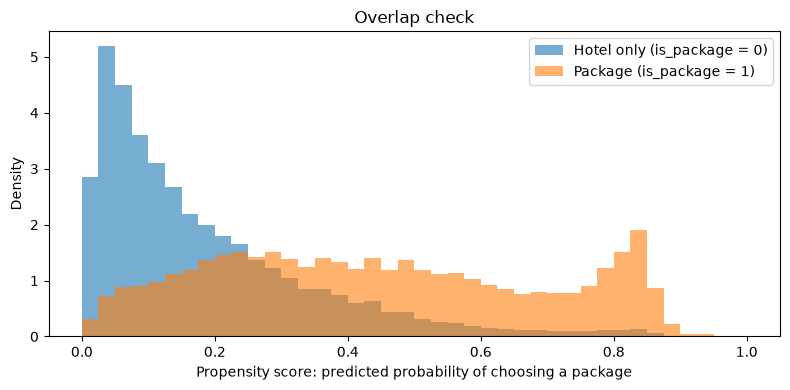

Share with propensity score < 0.05: 15.8%
Share with propensity score > 0.95: 0.0%


In [12]:
plt.figure(figsize=(8, 4))
bins = np.linspace(0, 1, 41)
plt.hist(ps[t == 0], bins=bins, alpha=0.6, density=True, label='Hotel only (is_package = 0)')
plt.hist(ps[t == 1], bins=bins, alpha=0.6, density=True, label='Package (is_package = 1)')
plt.xlabel('Propensity score: predicted probability of choosing a package')
plt.ylabel('Density')
plt.title('Overlap check')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Share with propensity score < 0.05: {(ps < 0.05).mean():.1%}")
print(f"Share with propensity score > 0.95: {(ps > 0.95).mean():.1%}")

**Reading the chart:**

- Every range with package users also has hotel-only users → the **ATT is reliable**.
- 16% of users had under a 5% chance of choosing a package (e.g. people who need no flight). There is no realistic package version of them, so the **ATE is less reliable**.

### Summary of results

In [13]:
summary = pd.DataFrame({
    'Method': ['Simple comparison (no adjustment)', 'Linear regression',
               'Propensity score weighting, ATE', 'Propensity score weighting, ATT'],
    'Effect (percentage points)': [naive_effect * 100, effect_linear * 100, ate * 100, att * 100],
}).round(2)
summary

,Method,Effect (percentage points)
0,Simple comparison (no adjustment),-4.87
1,Linear regression,-2.74
2,"Propensity score weighting, ATE",-4.07
3,"Propensity score weighting, ATT",-2.08


## 8. Refute: stress tests

Each test tries to break the ATE from propensity score weighting.

| Test | What I do | Pass if |
|---|---|---|
| Placebo | Shuffle the package indicator | Effect ≈ 0 |
| Random common cause | Add a random column as a control | Effect unchanged |
| Data subset | Re-estimate on a random 80% of rows, three times | Effect stable |

Passing shows that the method does not create an effect from nothing. It cannot rule out a missing factor.

In [17]:
rng = np.random.default_rng(966)   # fixed random numbers, so the results can be repeated

# Test 1: placebo. Shuffling t breaks any real link between the package and the booking.
t_shuffled = rng.permutation(t)
ate_placebo, _, _ = ipw_effect(X, t_shuffled, y)
print(f"Test 1 (placebo): before {ate * 100:+.2f} -> after shuffling {ate_placebo * 100:+.2f} percentage points")

Test 1 (placebo): before -4.07 -> after shuffling -0.10 percentage points


In [18]:
# Test 2: random common cause. Add one column of random numbers that is not related to anything.
X_with_noise = X.assign(random_noise=rng.normal(size=len(X)))
ate_noise, _, _ = ipw_effect(X_with_noise, t, y)
print(f"Test 2 (random common cause): before {ate * 100:+.2f} -> with random column {ate_noise * 100:+.2f} percentage points")

Test 2 (random common cause): before -4.07 -> with random column -4.07 percentage points


In [19]:
# Test 3: data subset. Recalculate with a random 80% of the data, 3 times.
subset_results = []
for i in range(3):
    rows = rng.choice(len(X), size=int(len(X) * 0.8), replace=False)
    ate_subset, _, _ = ipw_effect(X.iloc[rows], t[rows], y[rows])
    subset_results.append(ate_subset)
    print(f"Test 3 (data subset), run {i + 1}: {ate_subset * 100:+.2f} percentage points")

print(f"Average of 3 runs: {np.mean(subset_results) * 100:+.2f} (original {ate * 100:+.2f})")

Test 3 (data subset), run 1: -3.96 percentage points
Test 3 (data subset), run 2: -4.11 percentage points
Test 3 (data subset), run 3: -4.15 percentage points
Average of 3 runs: -4.07 (original -4.07)


## 9. What the results mean

| Method | Bookings per 100 clicks |
|---|---:|
| Simple comparison | −4.9 |
| Linear regression | −2.7 |
| Weighting, everyone (ATE) | −4.1 |
| **Weighting, package users (ATT)** | **−2.1** |

- **Main finding:** for package users, the package accounts for 2.1 fewer bookings per 100 clicks, less than half of the 4.9 in the simple comparison. The rest comes from who chooses packages.
- **Robustness:** with a shuffled (fake) package indicator the effect drops to about 0 (−0.1); adding a random column or using 80% of the data does not change it (−4.0 to −4.2). Linear regression (−2.7) gives a similar answer.
- **Caveat:** each row is a click, not a person. Package buyers may simply click more before booking.

**Next steps:** estimate individual treatment effects (who the package helps), measure per user instead of per click, and confirm with an A/B test.